# Data Cleaning: Titanic Passenger Dataset

**Prepared by:** Saurabh Shukla
**Email:** saurabhshuklant@gmail.com
**Track:** Data Analytics | Level 1 | Task 3
**Tools:** Python, pandas, numpy, matplotlib, seaborn, Jupyter Notebook

## Introduction

Real-world data is almost never ready to analyse. It arrives with missing values, wrong data types, inconsistent text, impossible numbers and extreme values, and any model or chart built on top of it inherits every one of those problems. Data cleaning is the step that makes the rest of the analysis trustworthy.

In this project I take the well-known **Titanic passenger dataset** (891 passengers) and turn it into a clean, analysis-ready dataset. Instead of simply "fixing things", I follow a fixed process and **document every decision**:

1. Audit the raw data and produce a **data quality report**
2. Standardise text and formatting
3. Remove duplicates
4. Handle missing values (with a justified strategy for each column)
5. Detect and decide what to do with outliers
6. Correct data types
7. Validate the result, compare **before vs after**, and save the clean file

**About the dataset**

| Column | Description |
|---|---|
| PassengerId | Unique ID of the passenger |
| Survived | 1 = survived, 0 = did not survive |
| Pclass | Ticket class (1 = first, 2 = second, 3 = third) |
| Name | Passenger's full name (includes a title such as Mr., Mrs., Miss.) |
| Sex | Male / female |
| Age | Age in years (fractional for infants) |
| SibSp | Number of siblings / spouses aboard |
| Parch | Number of parents / children aboard |
| Ticket | Ticket number |
| Fare | Ticket price |
| Cabin | Cabin number |
| Embarked | Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton) |

**A note on what "messy" means here.** I did not assume what is wrong with this data; I checked every item on the cleaning checklist. As the audit will show, the Titanic data has serious *missing-value*, *data-type*, *outlier* and *text-embedded-information* problems, but it has **no exact duplicate rows** and **no date columns**. Where a checklist item does not apply (or turns out to be clean), I say so and show the evidence rather than inventing a problem.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

print('Libraries loaded.')

Libraries loaded.


## 1. Loading the Raw Data

I keep an untouched copy of the raw data (`raw`) so that I can always compare against it at the end.

In [2]:
raw = pd.read_csv('titanic.csv')
df = raw.copy()          # all cleaning is done on this copy

print('Shape (rows, columns):', raw.shape)
raw.head(8)

Shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S


## 2. Data Quality Report

Before changing anything, I measure exactly how bad the data is. The report covers four things: **null values**, **duplicate rows**, **data type issues** and **value-range anomalies**, plus a check of text consistency.

### 2.1 Null values and data types

In [3]:
quality = pd.DataFrame({
    'Data type': raw.dtypes.astype(str),
    'Non-null': raw.notnull().sum(),
    'Nulls': raw.isnull().sum(),
    'Null %': (raw.isnull().mean() * 100).round(2),
    'Unique values': raw.nunique()
})
quality

,Data type,Non-null,Nulls,Null %,Unique values
PassengerId,int64,891,0,0.00,891
Survived,int64,891,0,0.00,2
Pclass,int64,891,0,0.00,3
Name,str,891,0,0.00,891
Sex,str,891,0,0.00,2
Age,float64,714,177,19.87,88
SibSp,int64,891,0,0.00,7
Parch,int64,891,0,0.00,7
Ticket,str,891,0,0.00,681
Fare,float64,891,0,0.00,248


In [4]:
total_cells = raw.shape[0] * raw.shape[1]
print('Total cells                 :', f'{total_cells:,}')
print('Total null cells            :', raw.isnull().sum().sum())
print('Overall null percentage     :', round(raw.isnull().sum().sum() / total_cells * 100, 2), '%')
print('Columns that contain nulls  :', (raw.isnull().sum() > 0).sum(), 'of', raw.shape[1])
print('Rows with at least one null :', raw.isnull().any(axis=1).sum(), 'of', len(raw))

Total cells                 : 10,692
Total null cells            : 866
Overall null percentage     : 8.1 %
Columns that contain nulls  : 3 of 12
Rows with at least one null : 708 of 891


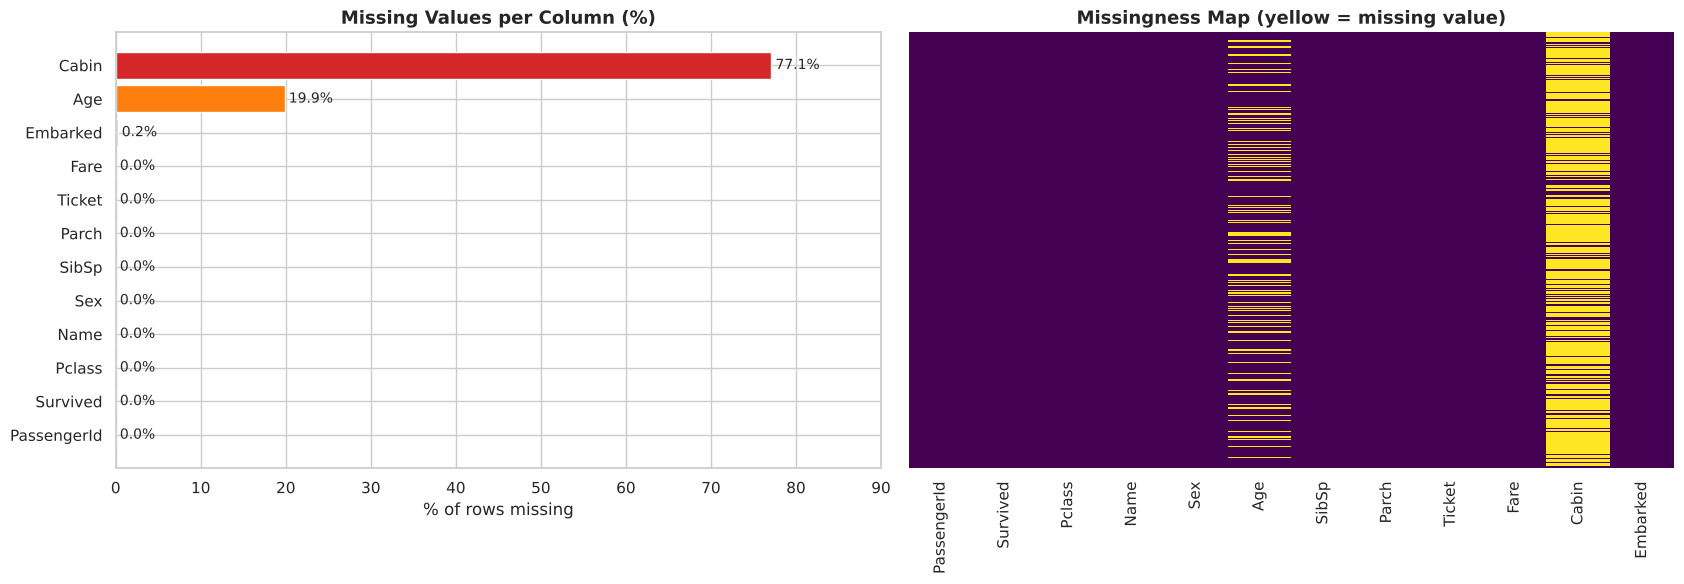

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# missing % per column
miss = (raw.isnull().mean() * 100).sort_values(ascending=True)
colors = ['#d62728' if v > 50 else '#ff7f0e' if v > 5 else '#2ca02c' if v == 0 else '#f2c744' for v in miss.values]
bars = axes[0].barh(miss.index, miss.values, color=colors)
axes[0].bar_label(bars, fmt='%.1f%%', padding=3, fontsize=10)
axes[0].set_title('Missing Values per Column (%)')
axes[0].set_xlabel('% of rows missing')
axes[0].set_xlim(0, 90)

# missingness map
sns.heatmap(raw.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[1])
axes[1].set_title('Missingness Map (yellow = missing value)')

plt.tight_layout()
plt.show()

**Observations**

- Only **3 of the 12 columns contain nulls**, but they are a mix of very different problems:
  - **Cabin: 687 missing (77.1%)**, so most passengers have no cabin recorded.
  - **Age: 177 missing (19.9%)**, which is a lot for a column that is important for analysis.
  - **Embarked: 2 missing (0.2%)**, a tiny gap.
- In total **866 of 10,692 cells (8.1%)** are empty, spread over **708 of the 891 rows**. This matters: if I simply deleted every row with a null I would throw away about 79% of the data. Row deletion is not an option for the main strategy.
- The missingness map shows that Cabin is almost entirely missing, while Age is missing in scattered patches.

### 2.2 Is the missing data random?

Before choosing a strategy I want to know *why* values are missing. If the gaps follow a pattern, filling them with a plain average could be wrong.

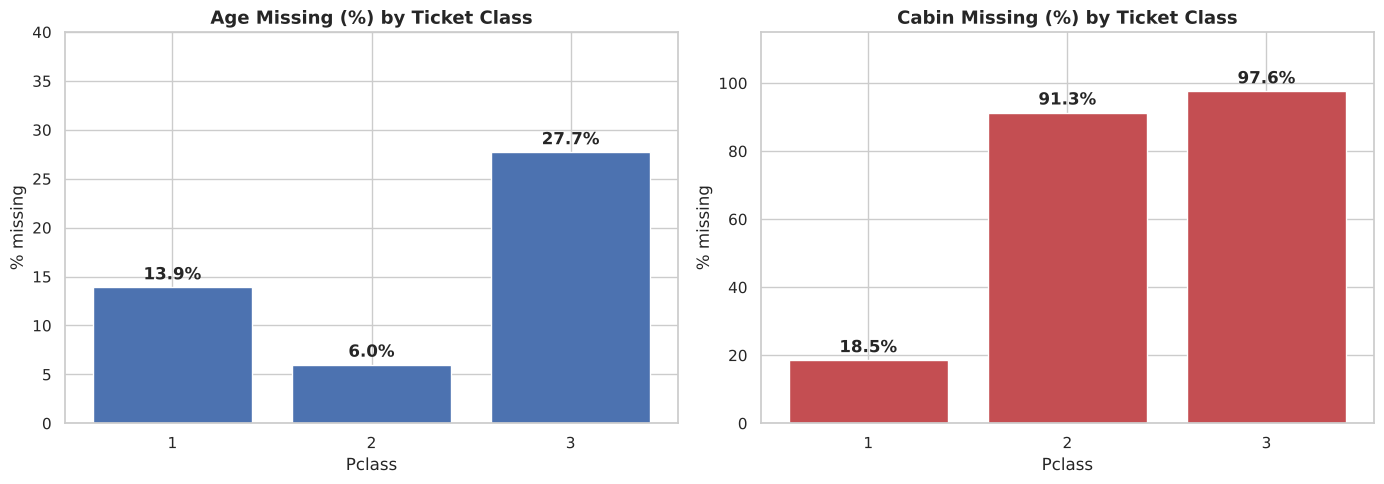

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

age_missing = raw.groupby('Pclass')['Age'].apply(lambda s: s.isnull().mean() * 100)
b1 = axes[0].bar(age_missing.index.astype(str), age_missing.values, color='#4c72b0')
axes[0].bar_label(b1, fmt='%.1f%%', padding=3, fontweight='bold')
axes[0].set_title('Age Missing (%) by Ticket Class')
axes[0].set_xlabel('Pclass')
axes[0].set_ylabel('% missing')
axes[0].set_ylim(0, 40)

cabin_missing = raw.groupby('Pclass')['Cabin'].apply(lambda s: s.isnull().mean() * 100)
b2 = axes[1].bar(cabin_missing.index.astype(str), cabin_missing.values, color='#c44e52')
axes[1].bar_label(b2, fmt='%.1f%%', padding=3, fontweight='bold')
axes[1].set_title('Cabin Missing (%) by Ticket Class')
axes[1].set_xlabel('Pclass')
axes[1].set_ylabel('% missing')
axes[1].set_ylim(0, 115)

plt.tight_layout()
plt.show()

**Observations**

- **Age** is missing more often in **third class (about 28%)** than in first class (about 14%). So the gaps are not purely random, and the imputation should take class into account.
- **Cabin** is missing for about **98% of third-class passengers** but only about **19% of first-class passengers**. The cabin was simply recorded for wealthy passengers and not for others. This means a missing Cabin is not a data error; it carries information (it tells us the passenger probably did not have a recorded cabin). I should keep that information, not fill it in with a made-up cabin.

### 2.3 Duplicates, text consistency and value-range anomalies

In [7]:
print('--- Duplicate checks ---')
print('Exact duplicate rows                       :', raw.duplicated().sum())
print('Duplicate rows ignoring PassengerId        :', raw.drop(columns='PassengerId').duplicated().sum())
print('Duplicate PassengerIds                     :', raw['PassengerId'].duplicated().sum())
print('Duplicate passenger names                  :', raw['Name'].duplicated().sum())
print('Tickets shared by more than one passenger  :', raw['Ticket'].duplicated().sum(), '(families / groups, not duplicates)')

print()
print('--- Text consistency checks ---')
print('Names with leading/trailing spaces :', (raw['Name'] != raw['Name'].str.strip()).sum())
print('Names with double spaces           :', raw['Name'].str.contains(r'\s{2,}').sum())
print('Tickets with spaces at the ends    :', (raw['Ticket'] != raw['Ticket'].str.strip()).sum())
print('Tickets not fully uppercase        :', (raw['Ticket'] != raw['Ticket'].str.upper()).sum())
print('Sex values                         :', raw['Sex'].unique().tolist())
print('Embarked values                    :', raw['Embarked'].unique().tolist())
print('Cabin entries with several cabins  :', raw['Cabin'].dropna().str.contains(' ').sum())

--- Duplicate checks ---
Exact duplicate rows                       : 0
Duplicate rows ignoring PassengerId        : 0
Duplicate PassengerIds                     : 0
Duplicate passenger names                  : 0
Tickets shared by more than one passenger  : 210 (families / groups, not duplicates)

--- Text consistency checks ---
Names with leading/trailing spaces : 2
Names with double spaces           : 0
Tickets with spaces at the ends    : 0
Tickets not fully uppercase        : 6
Sex values                         : ['male', 'female']
Embarked values                    : ['S', 'C', 'Q', nan]
Cabin entries with several cabins  : 24


In [8]:
# Value-range and logic checks
age_known = raw['Age'].dropna()
checks = pd.DataFrame([
    ['Survived not 0 or 1',               (~raw['Survived'].isin([0, 1])).sum(),   'Valid binary flag'],
    ['Pclass not 1, 2 or 3',              (~raw['Pclass'].isin([1, 2, 3])).sum(),  'Valid'],
    ['Negative Age',                      (age_known < 0).sum(),                   'Valid'],
    ['Age above 100',                     (age_known > 100).sum(),                 'Valid (oldest passenger is 80)'],
    ['Age below 1 year (infants)',        (age_known < 1).sum(),                   'Real infants stored as fractions, valid'],
    ['Age with .5 (estimated ages)',      ((age_known % 1) == 0.5).sum(),          'Estimated ages, kept as they are'],
    ['Negative SibSp or Parch',           ((raw['SibSp'] < 0) | (raw['Parch'] < 0)).sum(), 'Valid'],
    ['Negative Fare',                     (raw['Fare'] < 0).sum(),                 'Valid'],
    ['Fare equal to 0',                   (raw['Fare'] == 0).sum(),                'SUSPICIOUS: a free ticket, investigated below'],
], columns=['Check', 'Rows flagged', 'Verdict'])
checks

,Check,Rows flagged,Verdict
0,Survived not 0 or 1,0,Valid binary flag
1,"Pclass not 1, 2 or 3",0,Valid
2,Negative Age,0,Valid
3,Age above 100,0,Valid (oldest passenger is 80)
4,Age below 1 year (infants),7,"Real infants stored as fractions, valid"
5,Age with .5 (estimated ages),18,"Estimated ages, kept as they are"
6,Negative SibSp or Parch,0,Valid
7,Negative Fare,0,Valid
8,Fare equal to 0,15,"SUSPICIOUS: a free ticket, investigated below"


In [9]:
# Investigate the zero-fare passengers
zero_fare = raw[raw['Fare'] == 0]
print('Passengers with Fare = 0:', len(zero_fare))
print()
print('By ticket class:', zero_fare['Pclass'].value_counts().sort_index().to_dict())
print('By sex         :', zero_fare['Sex'].value_counts().to_dict())
print('By port        :', zero_fare['Embarked'].value_counts().to_dict())
print('Survival rate  :', round(zero_fare['Survived'].mean() * 100, 1), '%  (overall:', round(raw['Survived'].mean() * 100, 1), '%)')
print("Ticket labelled 'LINE':", (zero_fare['Ticket'] == 'LINE').sum(), 'of the zero-fare passengers;', (raw['Ticket'] == 'LINE').sum(), 'passengers hold a LINE ticket in total')
zero_fare[['PassengerId', 'Name', 'Pclass', 'Age', 'Ticket', 'Fare']].head(6)

Passengers with Fare = 0: 15

By ticket class: {1: 5, 2: 6, 3: 4}
By sex         : {'male': 15}
By port        : {'S': 15}
Survival rate  : 6.7 %  (overall: 38.4 %)
Ticket labelled 'LINE': 4 of the zero-fare passengers; 4 passengers hold a LINE ticket in total


,PassengerId,Name,Pclass,Age,Ticket,Fare
179,180,"Leonard, Mr. Lionel",3,36.0,LINE,0.0
263,264,"Harrison, Mr. William",1,40.0,112059,0.0
271,272,"Tornquist, Mr. William Henry",3,25.0,LINE,0.0
277,278,"Parkes, Mr. Francis ""Frank""",2,NaN,239853,0.0
302,303,"Johnson, Mr. William Cahoone Jr",3,19.0,LINE,0.0
413,414,"Cunningham, Mr. Alfred Fleming",2,NaN,239853,0.0


In [10]:
# Title vs Age logic check (a 'Mr.' should not be a small child)
raw_title = raw['Name'].str.extract(r',\s*([^\.]+)\.')[0].str.strip()
odd = raw[(raw_title == 'Mr') & (raw['Age'] < 16)]
print("Passengers titled 'Mr' but younger than 16:", len(odd))
odd[['PassengerId', 'Name', 'Age', 'SibSp', 'Parch']]

Passengers titled 'Mr' but younger than 16: 4


,PassengerId,Name,Age,SibSp,Parch
352,353,"Elias, Mr. Tannous",15.0,1,1
683,684,"Goodwin, Mr. Charles Edward",14.0,5,2
686,687,"Panula, Mr. Jaako Arnold",14.0,4,1
731,732,"Hassan, Mr. Houssein G N",11.0,0,0


**Observations: the data quality report in summary**

| Area | Finding |
|---|---|
| **Nulls** | Age 177 (19.9%), Cabin 687 (77.1%), Embarked 2 (0.2%) |
| **Duplicates** | **0 exact duplicates**, 0 duplicate IDs, 0 duplicate names. The 210 repeated ticket numbers are families and groups travelling together, so they are legitimate. |
| **Data types** | `PassengerId` is an integer but is really an identifier; `Pclass` is an integer but is really a category; `Sex`, `Embarked` are free text although they only hold a few labels. |
| **Text consistency** | **2 names have extra spaces**, and some ticket numbers are not uppercase. `Sex` is consistently lowercase, `Embarked` uses single-letter codes that are not self-explanatory. |
| **Embedded information** | `Name` contains the passenger's **title** (Mr, Mrs, Miss, Master...), which is useful for filling in missing ages. `Cabin` has its **deck letter** in the first character, and 24 passengers have several cabins in one cell. |
| **Range anomalies** | No negative or impossible values. **15 passengers have Fare = 0**, which needs a decision. |

Details on the anomalies:

- The **15 zero-fare passengers are all male, all boarded at Southampton, and are spread over all three classes** (5 first, 6 second, 4 third). Four of them hold a ticket literally labelled `LINE`, and every passenger with that ticket has a fare of 0. That pattern does not look like random data-entry errors; it looks like a special ticket type or group (for example staff or complimentary tickets). Only 1 of the 15 survived (6.7%, against 38.4% overall). I will treat these as **real values**.
- The "Mr under 16" check finds **4 passengers aged 11 to 15 who carry the title Mr**. That is unusual, because boys were normally addressed as "Master", but it is not impossible, and nothing in the data (family size, ticket) contradicts their ages. I cannot prove these are errors, so I keep them exactly as recorded.

## 3. Cleaning the Data

I record every change in a **cleaning log** (step, column, issue, action, rows affected), which is shown in full at the end of the notebook.

In [11]:
cleaning_log = []

def log_step(step, column, issue, action, rows):
    cleaning_log.append({'Step': step, 'Column': column, 'Issue found': issue,
                         'Action taken': action, 'Rows affected': rows})

print('Cleaning log ready.')

Cleaning log ready.


### Step 1: Standardising text and formatting

The checklist example is `"Male" / "male" / "M"` becoming one consistent value. The same idea applies here:

- **Name**: remove extra spaces.
- **Ticket**: remove spaces at the ends and make everything uppercase so that "Fa 265302" and "FA 265302" cannot be treated as different tickets.
- **Sex**: `male` / `female` is consistent, but I convert it to proper capitalisation (`Male` / `Female`) so that labels in charts and reports look professional.
- **Embarked**: replace the codes `S`, `C`, `Q` with the port names, because a code means nothing to someone reading the data later.

There are **no date columns** in this dataset, so date-format standardisation is not applicable.

In [12]:
# Name: strip and collapse repeated spaces
name_before = df['Name'].copy()
df['Name'] = df['Name'].str.strip().str.replace(r'\s+', ' ', regex=True)
n_name = (name_before != df['Name']).sum()

# Ticket: strip and uppercase
ticket_before = df['Ticket'].copy()
df['Ticket'] = df['Ticket'].str.strip().str.upper()
n_ticket = (ticket_before != df['Ticket']).sum()

# Sex: consistent capitalisation
sex_before = df['Sex'].copy()
df['Sex'] = df['Sex'].str.strip().str.title()
n_sex = (sex_before != df['Sex']).sum()

# Embarked: codes -> port names (missing values stay missing for now)
port_names = {'S': 'Southampton', 'C': 'Cherbourg', 'Q': 'Queenstown'}
n_port = df['Embarked'].notnull().sum()
df['Embarked'] = df['Embarked'].str.strip().str.upper().map(port_names)

log_step('1. Standardise text', 'Name', 'Leading/trailing/double spaces', 'Stripped and collapsed spaces', int(n_name))
log_step('1. Standardise text', 'Ticket', 'Inconsistent letter case', 'Stripped and converted to uppercase', int(n_ticket))
log_step('1. Standardise text', 'Sex', 'Lowercase labels', 'Converted to Male / Female', int(n_sex))
log_step('1. Standardise text', 'Embarked', 'Unclear single-letter codes', 'Mapped S/C/Q to Southampton/Cherbourg/Queenstown', int(n_port))

print('Names fixed   :', n_name)
print('Tickets fixed :', n_ticket)
print('Sex relabelled:', n_sex)
print('Ports renamed :', n_port)
print()
print('Sex values     :', df['Sex'].unique().tolist())
print('Embarked values:', df['Embarked'].unique().tolist())

Names fixed   : 2
Tickets fixed : 6
Sex relabelled: 891
Ports renamed : 889

Sex values     : ['Male', 'Female']
Embarked values: ['Southampton', 'Cherbourg', 'Queenstown', nan]


**Decision:** only a handful of names and tickets needed fixing, but these are exactly the kind of invisible differences that break joins and group-by operations later, so it is worth doing. Sex and Embarked values are now consistent and readable.

### Step 2: Duplicate removal

In [13]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
removed = rows_before - len(df)

log_step('2. Duplicates', 'All columns', 'Checked for exact duplicate rows', 'drop_duplicates() applied', removed)

print('Rows before:', rows_before)
print('Rows after :', len(df))
print('Duplicate rows removed:', removed)

Rows before: 891
Rows after : 891
Duplicate rows removed: 0


**Decision:** **0 duplicate rows were found, so 0 were removed.** I checked several ways (exact duplicates, duplicates ignoring the ID, duplicate IDs and duplicate names) and the dataset is clean on this point. The repeated ticket numbers were deliberately *not* removed because they belong to different people travelling on a shared ticket.

### Step 3: Extracting the passenger Title (needed to fill in Age)

The `Name` column hides a very useful piece of information: the title (Mr, Mrs, Miss, Master...). It is a strong clue to a person's age, because "Master" is used for young boys and "Miss" is used mostly for younger women. I extract it now because I will use it to fill in the missing ages.

Rare titles are grouped together and French forms are mapped to their English equivalents (Mlle = Miss, Mme = Mrs, Ms = Miss), so every group has enough people to give a stable median.

In [14]:
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.')[0].str.strip()
print('Titles found in the data:')
print(df['Title'].value_counts().to_dict())

df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
main_titles = ['Mr', 'Mrs', 'Miss', 'Master']
df['Title'] = df['Title'].where(df['Title'].isin(main_titles), 'Rare')

log_step('3. Feature extraction', 'Name -> Title', 'Title hidden inside Name', 'Extracted Title; merged Mlle/Ms->Miss, Mme->Mrs, others->Rare', len(df))

print()
print('Titles after grouping:')
print(df['Title'].value_counts())

Titles found in the data:
{'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Major': 2, 'Mlle': 2, 'Col': 2, 'Don': 1, 'Mme': 1, 'Ms': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'the Countess': 1, 'Jonkheer': 1}

Titles after grouping:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


### Step 4: Handling missing values

Each column gets its own strategy, chosen from what the missing-data analysis showed.

#### 4a. Embarked (2 missing): mode imputation

In [15]:
df[df['Embarked'].isnull()][['PassengerId', 'Name', 'Pclass', 'Ticket', 'Fare', 'Cabin']]

,PassengerId,Name,Pclass,Ticket,Fare,Cabin
61,62,"Icard, Miss. Amelie",1,113572,80.0,B28
829,830,"Stone, Mrs. George Nelson (Martha Evelyn)",1,113572,80.0,B28


In [16]:
print('Port of embarkation, first-class passengers only:')
print(df[df['Pclass'] == 1]['Embarked'].value_counts())
print()
print('Port of embarkation, all passengers:')
print(df['Embarked'].value_counts())

embarked_mode = df['Embarked'].mode()[0]
n_fill = df['Embarked'].isnull().sum()
df['Embarked'] = df['Embarked'].fillna(embarked_mode)

log_step('4a. Missing values', 'Embarked', '2 missing values (0.2%)', f'Mode imputation with {embarked_mode}', int(n_fill))
print()
print('Filled', n_fill, 'values with the mode:', embarked_mode)

Port of embarkation, first-class passengers only:
Embarked
Southampton    127
Cherbourg       85
Queenstown       2
Name: count, dtype: int64

Port of embarkation, all passengers:
Embarked
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

Filled 2 values with the mode: Southampton


**Decision: mode imputation (Southampton).**

- Embarked is a *categorical* column, so a mean or median makes no sense; the most frequent value (the mode) is the natural choice.
- Only 2 rows (0.2%) are affected, so the choice has almost no effect on the data overall.
- Both passengers are first-class women who share the **same ticket and the same cabin (B28)**, so they travelled together and must have boarded at the same port. Southampton is also the most common port among first-class passengers (127 of 214), which supports the choice.
- Row deletion would work too, but it would throw away two perfectly good rows for the sake of one missing field.

#### 4b. Age (177 missing): median imputation by Title and Class

The earlier analysis showed that Age is not missing completely at random (more gaps in third class), and that age depends a lot on title and class. So instead of one overall average, I fill each missing age with the **median age of passengers with the same Title and the same ticket class**.

In [17]:
# Lookup table of median ages (built from the known ages only)
age_lookup = df.groupby(['Title', 'Pclass'])['Age'].median().unstack().round(1)
print('Median age by Title and Pclass (used for imputation):')
age_lookup

Median age by Title and Pclass (used for imputation):


Pclass,1,2,3
Title,,,
Master,4.0,1.0,4.0
Miss,30.0,24.0,18.0
Mr,40.0,31.0,26.0
Mrs,40.0,32.0,31.0
Rare,48.5,46.5,NaN


In [18]:
age_before = df['Age'].copy()              # keep for the before/after comparison
df['Age_Imputed'] = df['Age'].isnull()     # flag so that imputed ages can always be identified

group_median = df.groupby(['Title', 'Pclass'])['Age'].transform('median')
title_median = df.groupby('Title')['Age'].transform('median')

# Fallback order: Title + Class median -> Title median -> overall median
df['Age'] = df['Age'].fillna(group_median).fillna(title_median).fillna(df['Age'].median())

log_step('4b. Missing values', 'Age', '177 missing values (19.9%)', 'Median imputation grouped by Title and Pclass; added Age_Imputed flag', int(df['Age_Imputed'].sum()))

comparison = pd.DataFrame({
    'Before (known ages only)': age_before.describe(),
    'After imputation': df['Age'].describe()
}).round(2)
print('Values imputed:', df['Age_Imputed'].sum())
print('Nulls left in Age:', df['Age'].isnull().sum())
comparison

Values imputed: 177
Nulls left in Age: 0


,Before (known ages only),After imputation
count,714.00,891.00
mean,29.70,29.14
std,14.53,13.49
min,0.42,0.42
25%,20.12,21.00
50%,28.00,26.00
75%,38.00,36.75
max,80.00,80.00


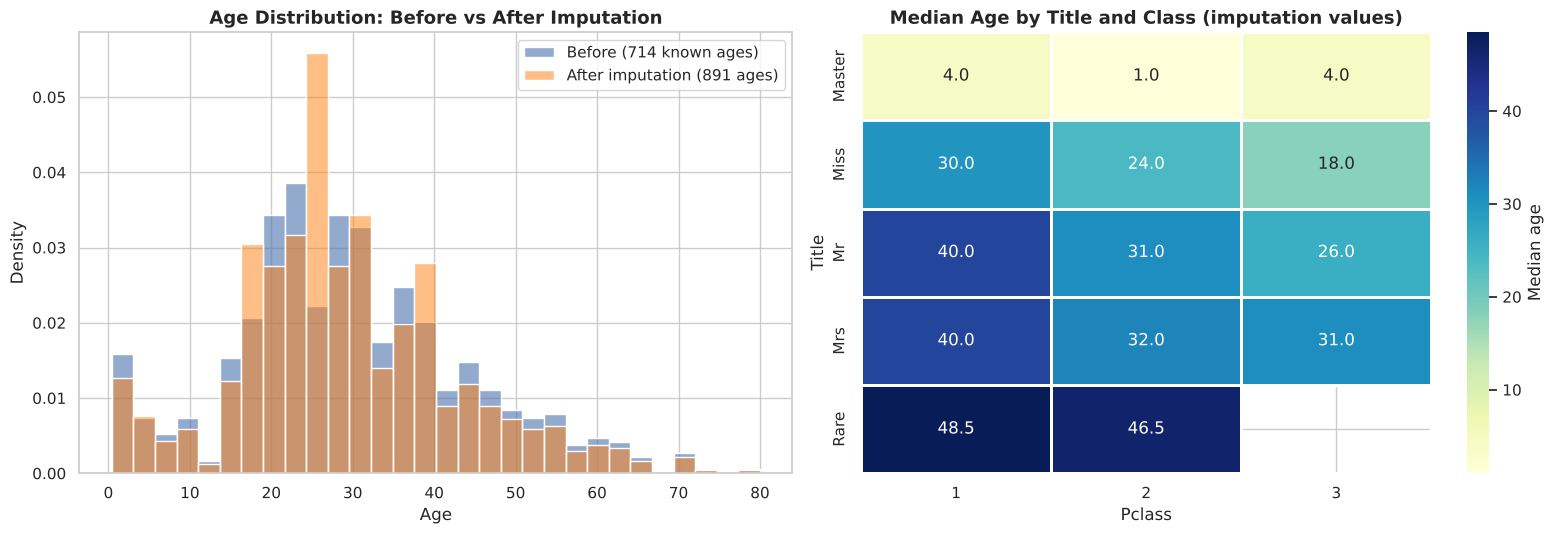

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.histplot(age_before.dropna(), bins=30, color='#4c72b0', alpha=0.6, label='Before (714 known ages)', ax=axes[0], stat='density')
sns.histplot(df['Age'], bins=30, color='#ff7f0e', alpha=0.5, label='After imputation (891 ages)', ax=axes[0], stat='density')
axes[0].set_title('Age Distribution: Before vs After Imputation')
axes[0].set_xlabel('Age')
axes[0].legend()

sns.heatmap(age_lookup, annot=True, fmt='.1f', cmap='YlGnBu', linewidths=1, linecolor='white',
            cbar_kws={'label': 'Median age'}, ax=axes[1])
axes[1].set_title('Median Age by Title and Class (imputation values)')

plt.tight_layout()
plt.show()

**Decision: grouped median imputation.**

- **Why median and not mean?** Age has a slightly right-skewed distribution with a few older passengers, and the median is not pulled around by those values.
- **Why group by Title and Class?** A single overall median (28) would give a 4-year-old "Master" an age of 28 and a 50-year-old first-class "Mrs" an age of 28. The heatmap shows that the typical age really does differ by group (for example a first-class Mr has a median of 40, while a "Master" is a young boy of about 1 to 4). Grouped imputation keeps those relationships intact.
- **Why not delete the rows?** 177 rows is 19.9% of the data; deleting them would lose a fifth of the passengers and bias the dataset towards first-class passengers (who have fewer missing ages).
- **Why not forward fill?** Forward fill assumes neighbouring rows are related, and in this dataset the row order has no meaning (it is just ID order), so it would copy the age of an unrelated passenger.
- The before/after histogram shows the overall shape of the age distribution is preserved. The summary table shows the cost: the **mean moves from 29.7 to 29.1, the median from 28 to 26, and the standard deviation shrinks from 14.5 to 13.5**, because many imputed values are the medians of big groups and so pile up in the middle of the distribution. This is the normal side effect of median imputation and is the reason I created the **`Age_Imputed` flag**: any later analysis can still include or exclude the imputed ages.

#### 4c. Cabin (687 missing): do not impute, extract Deck and a Has_Cabin flag instead

In [20]:
print('Cabin missing by class (%):')
print((df.groupby('Pclass')['Cabin'].apply(lambda s: s.isnull().mean() * 100)).round(1))
print()

df['Has_Cabin'] = df['Cabin'].notnull()
df['Deck'] = df['Cabin'].str[0].fillna('Unknown')

print('Deck counts:')
print(df['Deck'].value_counts())
print()
print('Survival rate by Has_Cabin:')
print((df.groupby('Has_Cabin')['Survived'].mean() * 100).round(1))

Cabin missing by class (%):
Pclass
1    18.5
2    91.3
3    97.6
Name: Cabin, dtype: float64

Deck counts:
Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

Survival rate by Has_Cabin:
Has_Cabin
False    30.0
True     66.7
Name: Survived, dtype: float64


In [21]:
n_cabin = df['Cabin'].isnull().sum()
df = df.drop(columns='Cabin')

log_step('4c. Missing values', 'Cabin', '687 missing values (77.1%)', 'Not imputed; created Has_Cabin flag and Deck (Unknown if missing); dropped raw Cabin', int(n_cabin))
print('Cabin column dropped. Remaining columns:')
print(df.columns.tolist())

Cabin column dropped. Remaining columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked', 'Title', 'Age_Imputed', 'Has_Cabin', 'Deck']


**Decision: column replacement (no imputation).**

- 77% of the values are missing, and there is **no reliable way to guess a cabin number**. Filling them in would mean inventing data, which is worse than leaving it blank.
- Mean, median or mode are meaningless for a cabin code, and forward fill would just copy a random neighbour's cabin.
- The missingness itself is informative (98% of third-class passengers have no cabin, against 19% in first class), so I keep that information in a new **`Has_Cabin`** flag. The flag does carry signal: 66.7% of passengers with a recorded cabin survived, against 30.0% of those without (this reflects class and position on the ship, not a causal effect of having a cabin).
- The first letter of a cabin is the **deck**, which is a real and useful piece of information for the 204 passengers who have one. Missing values become the explicit category **`Unknown`**.
- The raw Cabin column (with 687 nulls and multi-cabin entries) is then dropped because its useful content now lives in `Deck` and `Has_Cabin`.

### Step 5: Outlier detection

I use both methods from the checklist, the **IQR method** (values beyond 1.5 x IQR from the quartiles) and the **Z-score method** (|z| > 3), on every numeric column that measures something (Age, Fare, SibSp, Parch).

In [22]:
outlier_cols = ['Age', 'Fare', 'SibSp', 'Parch']
rows = []
for col in outlier_cols:
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_out = ((s < low) | (s > high)).sum()
    z_out = ((s - s.mean()) / s.std()).abs().gt(3).sum()
    rows.append([col, round(s.skew(), 2), round(low, 2), round(high, 2), iqr_out, z_out, s.min(), s.max()])

outlier_table = pd.DataFrame(rows, columns=['Column', 'Skewness', 'IQR lower fence', 'IQR upper fence',
                                            'Outliers (IQR)', 'Outliers (Z-score)', 'Min', 'Max'])
outlier_table

,Column,Skewness,IQR lower fence,IQR upper fence,Outliers (IQR),Outliers (Z-score),Min,Max
0,Age,0.47,-2.62,60.38,22,7,0.42,80.0000
1,Fare,4.79,-26.72,65.63,116,20,0.00,512.3292
2,SibSp,3.70,-1.50,2.50,46,30,0.00,8.0000
3,Parch,2.75,0.00,0.00,213,15,0.00,6.0000


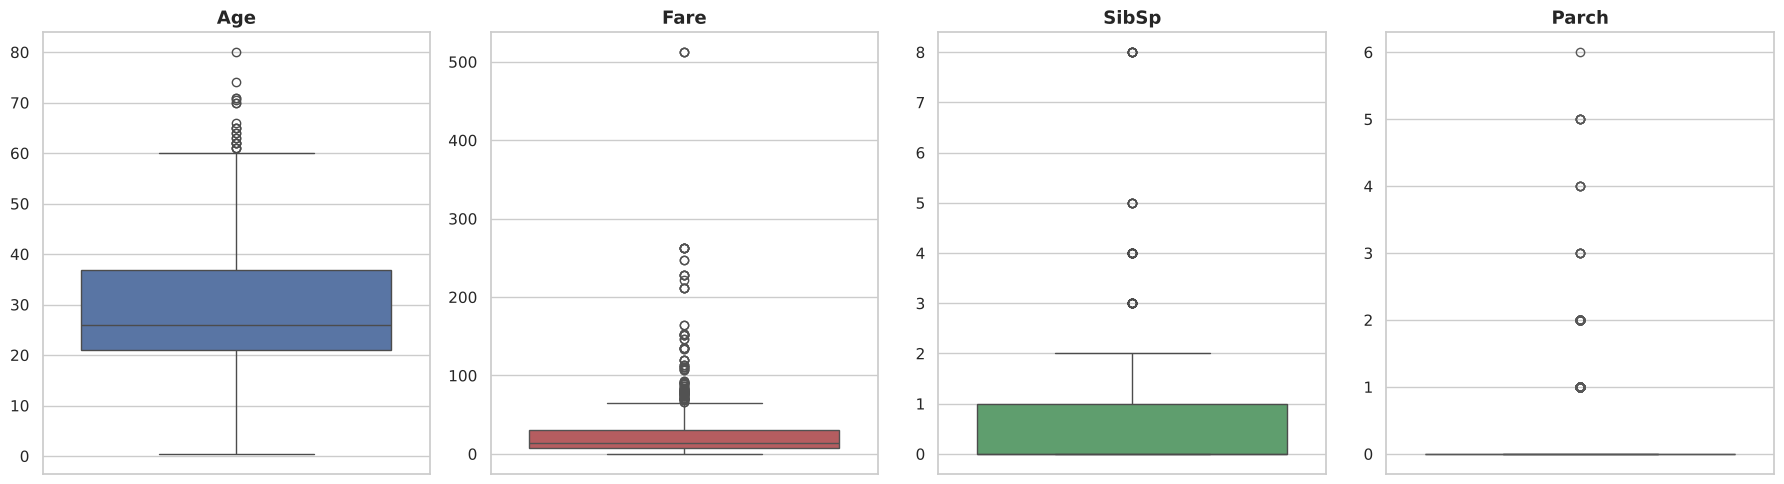

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col, c in zip(axes, outlier_cols, ['#4c72b0', '#c44e52', '#55a868', '#8172b2']):
    sns.boxplot(y=df[col], ax=ax, color=c)
    ax.set_title(col)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [24]:
# Look at the most extreme values to decide whether they are errors or real
print('Top 6 fares:')
print(df.nlargest(6, 'Fare')[['Name', 'Pclass', 'Fare', 'Ticket']].to_string(index=False))
print()
print('Oldest 5 passengers:')
print(df.loc[df['Age_Imputed'] == False].nlargest(5, 'Age')[['Name', 'Pclass', 'Age']].to_string(index=False))
print()
print('Largest families (SibSp):')
print(df.nlargest(4, 'SibSp')[['Name', 'SibSp', 'Parch', 'Ticket']].to_string(index=False))

Top 6 fares:
                              Name  Pclass     Fare   Ticket
                  Ward, Miss. Anna       1 512.3292 PC 17755
Cardeza, Mr. Thomas Drake Martinez       1 512.3292 PC 17755
            Lesurer, Mr. Gustave J       1 512.3292 PC 17755
    Fortune, Mr. Charles Alexander       1 263.0000    19950
        Fortune, Miss. Mabel Helen       1 263.0000    19950
    Fortune, Miss. Alice Elizabeth       1 263.0000    19950

Oldest 5 passengers:
                                Name  Pclass  Age
Barkworth, Mr. Algernon Henry Wilson       1 80.0
                 Svensson, Mr. Johan       3 74.0
           Goldschmidt, Mr. George B       1 71.0
             Artagaveytia, Mr. Ramon       1 71.0
                Connors, Mr. Patrick       3 70.5

Largest families (SibSp):
                        Name  SibSp  Parch   Ticket
  Sage, Master. Thomas Henry      8      2 CA. 2343
Sage, Miss. Constance Gladys      8      2 CA. 2343
         Sage, Mr. Frederick      8      2 CA. 2343
   

**Observations and decisions**

| Column | What the data shows | Decision |
|---|---|---|
| **Age** | 22 IQR outliers (mostly older passengers, upper fence about 60) and 7 by Z-score. The highest value is 80. | **Retain.** These are real elderly passengers, not errors. Nothing is impossible (no negative values, nothing above 100). |
| **Fare** | Heavily right-skewed (skewness 4.8). 116 IQR outliers. The top fares (about 512) belong to first-class passengers with expensive suites. | **Retain the original values, add `Fare_Log`.** These are real, expensive tickets. Capping or deleting them would erase the very difference between first and third class. For modelling the skew can be handled by the log version. |
| **SibSp** | 46 IQR outliers; the maximum is 8. The biggest values belong to one large family travelling on the same ticket. | **Retain.** Real family sizes. |
| **Parch** | The IQR method flags 213 rows, but this is a false alarm: more than 75% of passengers have 0, so Q1 = Q3 = 0 and the fences collapse to 0. Z-score flags 15. | **Retain.** The IQR rule is not suitable for a column that is mostly zeros. Values up to 6 are plausible family sizes. |
| **Fare = 0** | 15 passengers (from the quality report). | **Retain.** They look like a genuine group (all male, all Southampton, across classes), not random errors. Replacing them with an imputed fare would change real information. |

The general rule I follow: **an outlier is only removed when it is an error.** Here every extreme value is plausible, so nothing is deleted or capped. This keeps the full 891 rows.

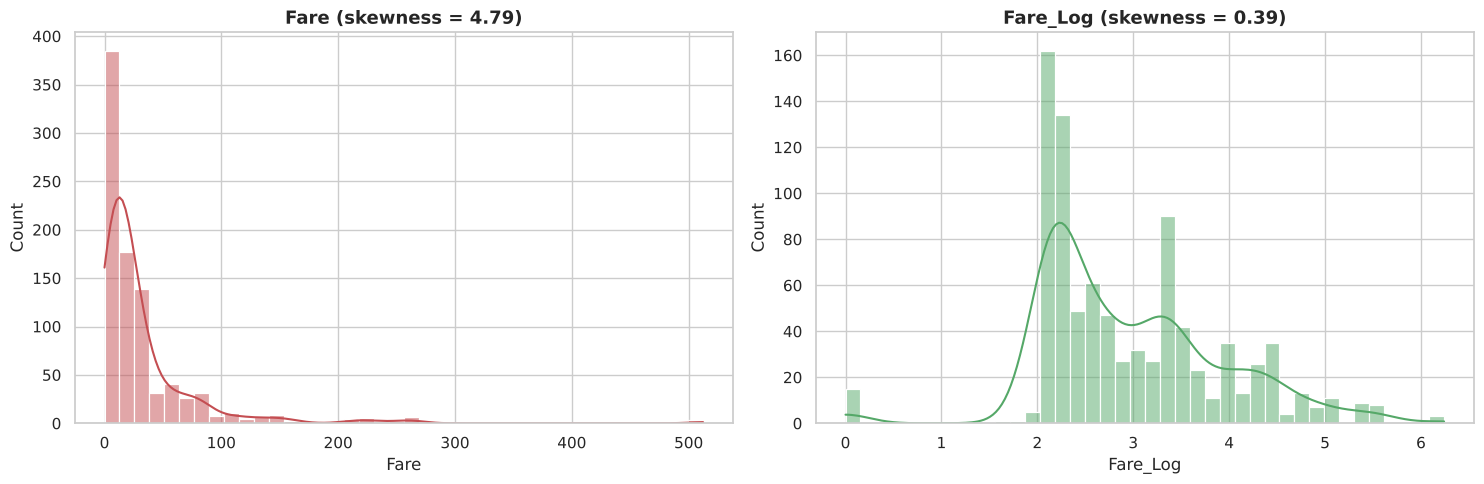

In [25]:
# Log-transform version of Fare to deal with the strong right skew
df['Fare_Log'] = np.log1p(df['Fare'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df['Fare'], bins=40, color='#c44e52', kde=True, ax=axes[0])
axes[0].set_title(f"Fare (skewness = {df['Fare'].skew():.2f})")
sns.histplot(df['Fare_Log'], bins=40, color='#55a868', kde=True, ax=axes[1])
axes[1].set_title(f"Fare_Log (skewness = {df['Fare_Log'].skew():.2f})")
plt.tight_layout()
plt.show()

log_step('5. Outliers', 'Age, SibSp, Parch', 'IQR/Z-score outliers, all plausible', 'Retained (no capping or removal)', 0)
log_step('5. Outliers', 'Fare', 'Strong right skew, 116 IQR outliers, 15 zero fares', 'Retained original; added Fare_Log = log(1 + Fare)', len(df))

**Observation:** the log transformation brings the skewness of Fare down from about 4.8 to about 0.4, so the log version is far better suited to models and charts that dislike heavy skew, while the original Fare is kept untouched for reporting.

### Step 6: Data type correction

A column's type should describe what the column *is*, not just what pandas guessed when reading the file.

| Column | Current type | Correct type | Reason |
|---|---|---|---|
| PassengerId | int64 | **string** | It is an identifier; you never add or average IDs |
| Pclass | int64 | **ordered category** (1 < 2 < 3) | A class label with a natural order, not a quantity |
| Sex, Embarked, Title, Deck | text | **category** | Only a few repeating labels; categories use less memory and are faster to group |
| Survived | int64 | **int8** (0/1) | Binary flag, kept numeric so survival rates can be averaged directly |
| SibSp, Parch | int64 | **int8** | Small counts (0 to 8) |
| Age, Fare, Fare_Log | float | float | Already correct |
| Age_Imputed, Has_Cabin | bool | bool | Already correct |
| Name, Ticket | text | string | Already correct |

There are no date columns to convert.

In [26]:
def kind(s):
    # simple classification of a column's data type
    if isinstance(s.dtype, pd.CategoricalDtype): return 'category'
    if pd.api.types.is_bool_dtype(s):            return 'bool'
    if pd.api.types.is_integer_dtype(s):         return 'integer'
    if pd.api.types.is_float_dtype(s):           return 'float'
    if pd.api.types.is_string_dtype(s):          return 'string'
    return 'other'

dtypes_before = df.dtypes.astype(str).copy()

df['PassengerId'] = df['PassengerId'].astype(str)
df['Pclass'] = pd.Categorical(df['Pclass'], categories=[1, 2, 3], ordered=True)
for col in ['Sex', 'Embarked', 'Title', 'Deck']:
    df[col] = df[col].astype('category')
df['Survived'] = df['Survived'].astype('int8')
df['SibSp'] = df['SibSp'].astype('int8')
df['Parch'] = df['Parch'].astype('int8')

# tidy column order
df = df[['PassengerId', 'Survived', 'Pclass', 'Name', 'Title', 'Sex', 'Age', 'Age_Imputed', 'SibSp', 'Parch',
         'Ticket', 'Fare', 'Fare_Log', 'Has_Cabin', 'Deck', 'Embarked']]

log_step('6. Data types', 'PassengerId, Pclass, Sex, Embarked, Title, Deck, Survived, SibSp, Parch',
         'Identifiers and labels stored as numbers/text', 'Converted to string / ordered category / int8', len(df))

pd.DataFrame({'Before': dtypes_before.reindex(df.columns), 'After': df.dtypes.astype(str)})

,Before,After
PassengerId,int64,str
Survived,int64,int8
Pclass,int64,category
Name,str,str
Title,str,category
Sex,str,category
Age,float64,float64
Age_Imputed,bool,bool
SibSp,int64,int8
Parch,int64,int8


### Step 7: Final validation

Rather than just assuming the cleaning worked, I test it. If any of these checks fails, the notebook stops with an error.

In [27]:
assert df.isnull().sum().sum() == 0,           'There are still null values'
assert df.duplicated().sum() == 0,             'There are duplicate rows'
assert df['PassengerId'].is_unique,            'PassengerId is not unique'
assert df['Survived'].isin([0, 1]).all(),      'Survived has invalid values'
assert df['Age'].between(0, 100).all(),        'Age out of range'
assert (df['Fare'] >= 0).all(),                'Negative fares'
assert df['Sex'].nunique() == 2,               'Unexpected Sex values'
assert set(df['Embarked'].unique()) == {'Southampton', 'Cherbourg', 'Queenstown'}, 'Unexpected Embarked values'
assert len(df) == len(raw),                    'Rows were lost during cleaning'

print('All validation checks passed.')
print('Final shape:', df.shape)
df.head(8)

All validation checks passed.
Final shape: (891, 16)


,PassengerId,Survived,Pclass,Name,Title,Sex,Age,Age_Imputed,SibSp,Parch,Ticket,Fare,Fare_Log,Has_Cabin,Deck,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",Mr,Male,22.0,False,1,0,A/5 21171,7.2500,2.110213,False,Unknown,Southampton
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",Mrs,Female,38.0,False,1,0,PC 17599,71.2833,4.280593,True,C,Cherbourg
2,3,1,3,"Heikkinen, Miss. Laina",Miss,Female,26.0,False,0,0,STON/O2. 3101282,7.9250,2.188856,False,Unknown,Southampton
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,Female,35.0,False,1,0,113803,53.1000,3.990834,True,C,Southampton
4,5,0,3,"Allen, Mr. William Henry",Mr,Male,35.0,False,0,0,373450,8.0500,2.202765,False,Unknown,Southampton
5,6,0,3,"Moran, Mr. James",Mr,Male,26.0,True,0,0,330877,8.4583,2.246893,False,Unknown,Queenstown
6,7,0,1,"McCarthy, Mr. Timothy J",Mr,Male,54.0,False,0,0,17463,51.8625,3.967694,True,E,Southampton
7,8,0,3,"Palsson, Master. Gosta Leonard",Master,Male,2.0,False,3,1,349909,21.0750,3.094446,False,Unknown,Southampton


## 4. Before vs After Summary

For **dtype accuracy** I compare every column's type with the type that best describes it (identifiers as strings, labels as categories, counts as integers, measurements as floats, flags as booleans).

In [28]:
ideal_before = {'PassengerId': 'string', 'Survived': 'integer', 'Pclass': 'category', 'Name': 'string', 'Sex': 'category',
                'Age': 'float', 'SibSp': 'integer', 'Parch': 'integer', 'Ticket': 'string', 'Fare': 'float',
                'Cabin': 'string', 'Embarked': 'category'}
ideal_after = {'PassengerId': 'string', 'Survived': 'integer', 'Pclass': 'category', 'Name': 'string', 'Title': 'category',
               'Sex': 'category', 'Age': 'float', 'Age_Imputed': 'bool', 'SibSp': 'integer', 'Parch': 'integer',
               'Ticket': 'string', 'Fare': 'float', 'Fare_Log': 'float', 'Has_Cabin': 'bool', 'Deck': 'category',
               'Embarked': 'category'}

def dtype_accuracy(data, ideal):
    ok = sum(kind(data[c]) == t for c, t in ideal.items())
    return ok, len(ideal)

def inconsistent_text(data):
    n = (data['Name'] != data['Name'].str.strip()).sum()
    n += (data['Ticket'] != data['Ticket'].str.upper()).sum()
    return int(n)

b_ok, b_tot = dtype_accuracy(raw, ideal_before)
a_ok, a_tot = dtype_accuracy(df, ideal_after)

summary = pd.DataFrame({
    'Before cleaning': [raw.shape[0], raw.shape[1], int(raw.isnull().sum().sum()), int((raw.isnull().sum() > 0).sum()),
                        round(raw.isnull().sum().sum() / raw.size * 100, 2), int(raw.duplicated().sum()),
                        inconsistent_text(raw), f'{b_ok} of {b_tot}  ({b_ok / b_tot * 100:.0f}%)',
                        round(raw.memory_usage(deep=True).sum() / 1024, 1)],
    'After cleaning':  [df.shape[0], df.shape[1], int(df.isnull().sum().sum()), int((df.isnull().sum() > 0).sum()),
                        round(df.isnull().sum().sum() / df.size * 100, 2), int(df.duplicated().sum()),
                        inconsistent_text(df), f'{a_ok} of {a_tot}  ({a_ok / a_tot * 100:.0f}%)',
                        round(df.memory_usage(deep=True).sum() / 1024, 1)]
}, index=['Row count', 'Column count', 'Total null cells', 'Columns containing nulls', 'Null % of all cells',
          'Duplicate rows', 'Inconsistent text entries (Name spaces, Ticket case)', 'Columns with correct dtype',
          'Memory usage (KB)'])
summary

,Before cleaning,After cleaning
Row count,891,891
Column count,12,16
Total null cells,866,0
Columns containing nulls,3,0
Null % of all cells,8.1,0.0
Duplicate rows,0,0
"Inconsistent text entries (Name spaces, Ticket case)",8,0
Columns with correct dtype,8 of 12 (67%),16 of 16 (100%)
Memory usage (KB),285.6,190.6


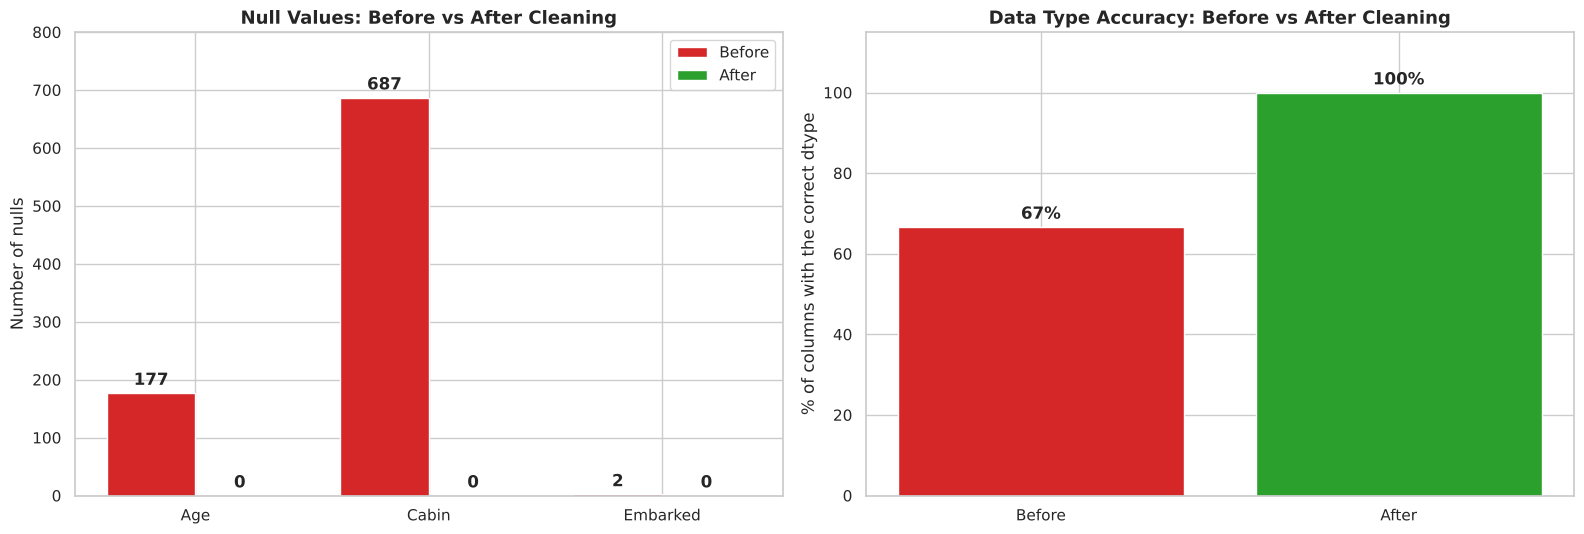

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

nulls_b = raw.isnull().sum()
nulls_b = nulls_b[nulls_b > 0]
x = np.arange(len(nulls_b))
w = 0.38
bb = axes[0].bar(x - w/2, nulls_b.values, w, color='#d62728', label='Before')
ba = axes[0].bar(x + w/2, [df[c].isnull().sum() if c in df.columns else 0 for c in nulls_b.index], w, color='#2ca02c', label='After')
axes[0].bar_label(bb, padding=3, fontweight='bold')
axes[0].bar_label(ba, padding=3, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(nulls_b.index)
axes[0].set_title('Null Values: Before vs After Cleaning')
axes[0].set_ylabel('Number of nulls')
axes[0].set_ylim(0, 800)
axes[0].legend()

acc = pd.Series({'Before': b_ok / b_tot * 100, 'After': a_ok / a_tot * 100})
bars = axes[1].bar(acc.index, acc.values, color=['#d62728', '#2ca02c'])
axes[1].bar_label(bars, fmt='%.0f%%', padding=3, fontweight='bold')
axes[1].set_title('Data Type Accuracy: Before vs After Cleaning')
axes[1].set_ylabel('% of columns with the correct dtype')
axes[1].set_ylim(0, 115)

plt.tight_layout()
plt.show()

**Observations**

- **Nulls fell from 866 to 0.** All three affected columns were resolved, each with a strategy that suited it (mode, grouped median, and a flag + deck column instead of invention).
- **No rows were lost** (891 before, 891 after). Every passenger was kept.
- **Duplicates stayed at 0**, as expected, since there were none to begin with.
- **Dtype accuracy rose from 67% to 100%**, and the dataset is also smaller in memory because of the category and small-integer types.
- The column count went from 12 to 16: one column (Cabin) was removed, and five were added (`Title`, `Age_Imputed`, `Fare_Log`, `Has_Cabin`, `Deck`). Each of them exists for a documented reason.

## 5. Complete Cleaning Log

In [30]:
log_df = pd.DataFrame(cleaning_log)
log_df

,Step,Column,Issue found,Action taken,Rows affected
0,1. Standardise text,Name,Leading/trailing/double spaces,Stripped and collapsed spaces,2
1,1. Standardise text,Ticket,Inconsistent letter case,Stripped and converted to uppercase,6
2,1. Standardise text,Sex,Lowercase labels,Converted to Male / Female,891
3,1. Standardise text,Embarked,Unclear single-letter codes,Mapped S/C/Q to Southampton/Cherbourg/Queenstown,889
4,2. Duplicates,All columns,Checked for exact duplicate rows,drop_duplicates() applied,0
5,3. Feature extraction,Name -> Title,Title hidden inside Name,"Extracted Title; merged Mlle/Ms->Miss, Mme->Mrs, others->Rare",891
6,4a. Missing values,Embarked,2 missing values (0.2%),Mode imputation with Southampton,2
7,4b. Missing values,Age,177 missing values (19.9%),Median imputation grouped by Title and Pclass; added Age_Imputed flag,177
8,4c. Missing values,Cabin,687 missing values (77.1%),Not imputed; created Has_Cabin flag and Deck (Unknown if missing); dropped raw Cabin,687
9,5. Outliers,"Age, SibSp, Parch","IQR/Z-score outliers, all plausible",Retained (no capping or removal),0


## 6. Saving the Cleaned Dataset

In [31]:
df.to_csv('titanic_cleaned.csv', index=False)

check = pd.read_csv('titanic_cleaned.csv')
print('Saved: titanic_cleaned.csv')
print('Re-loaded shape:', check.shape)
print('Nulls after re-loading:', check.isnull().sum().sum())
check.head()

Saved: titanic_cleaned.csv
Re-loaded shape: (891, 16)
Nulls after re-loading: 0


,PassengerId,Survived,Pclass,Name,Title,Sex,Age,Age_Imputed,SibSp,Parch,Ticket,Fare,Fare_Log,Has_Cabin,Deck,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",Mr,Male,22.0,False,1,0,A/5 21171,7.2500,2.110213,False,Unknown,Southampton
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",Mrs,Female,38.0,False,1,0,PC 17599,71.2833,4.280593,True,C,Cherbourg
2,3,1,3,"Heikkinen, Miss. Laina",Miss,Female,26.0,False,0,0,STON/O2. 3101282,7.9250,2.188856,False,Unknown,Southampton
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,Female,35.0,False,1,0,113803,53.1000,3.990834,True,C,Southampton
4,5,0,3,"Allen, Mr. William Henry",Mr,Male,35.0,False,0,0,373450,8.0500,2.202765,False,Unknown,Southampton


*Note: a CSV file stores plain text, so the category types (and the 1 < 2 < 3 ordering of `Pclass`) are not stored in the file. When the file is loaded again, these columns only need to be converted with `astype('category')`. The cleaning code above shows exactly how.*

### A quick proof that the data is analysis-ready

A good test of cleaning is that the data can immediately be used. Here is the survival rate by sex and ticket class, calculated directly from the cleaned dataset, with no further preparation needed.

Overall survival rate: 38.4 %


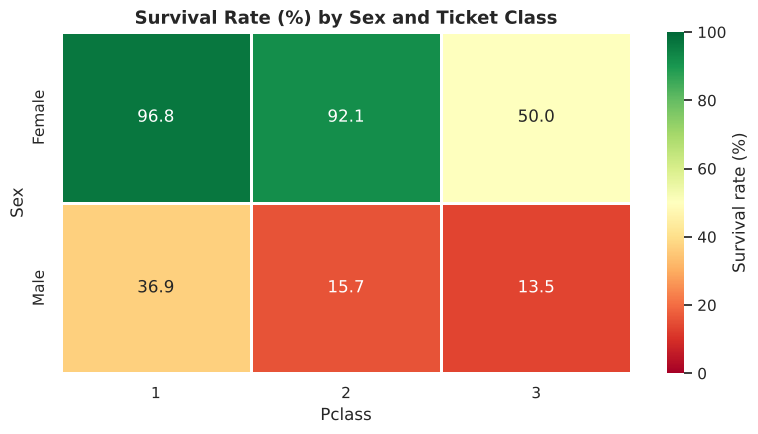

In [32]:
survival = df.pivot_table(index='Sex', columns='Pclass', values='Survived', aggfunc='mean', observed=True) * 100
print('Overall survival rate:', round(df['Survived'].mean() * 100, 1), '%')

plt.figure(figsize=(8, 4.5))
sns.heatmap(survival, annot=True, fmt='.1f', cmap='RdYlGn', vmin=0, vmax=100, linewidths=1, linecolor='white',
            cbar_kws={'label': 'Survival rate (%)'})
plt.title('Survival Rate (%) by Sex and Ticket Class')
plt.tight_layout()
plt.show()

**Observation:** the result is the well-known pattern of the disaster: women in first and second class survived at over 90%, while men in third class survived at only 13.5%. Seeing a clear and sensible pattern straight away is a good sign that the cleaning has not damaged the data.

## 7. Conclusion

I took the raw Titanic dataset through a complete, documented cleaning process:

- **Audit:** the quality report showed 866 null cells (Age 19.9%, Cabin 77.1%, Embarked 0.2%), wrongly typed columns, small text inconsistencies and a group of 15 zero-fare passengers.
- **Missing data:** each column was treated differently. `Embarked` used the mode, `Age` used a median grouped by Title and class (with an `Age_Imputed` flag for transparency), and `Cabin` was *not* imputed at all but turned into `Has_Cabin` and `Deck`.
- **Duplicates:** none were found, and I documented the evidence instead of pretending otherwise.
- **Standardisation:** names, tickets, sex and port values are now consistent and readable.
- **Outliers:** detected with both IQR and Z-score; every extreme value turned out to be real, so all were retained, and a log-transformed `Fare_Log` was added to handle the skew.
- **Data types:** all 16 columns now have the type that best describes them.
- **Result:** 891 rows kept, 0 nulls, 0 duplicates, 100% dtype accuracy, validated by automatic checks and saved as `titanic_cleaned.csv`.

### Key lessons from this exercise
1. **Look at *why* data is missing before filling it.** The pattern in Cabin and Age changed the strategy for both.
2. **Don't invent data.** For Cabin, guessing would have been worse than keeping the gap as information.
3. **An outlier is not automatically an error.** Deleting the expensive first-class fares would have destroyed real signal.
4. **Document and flag.** The cleaning log and the `Age_Imputed` flag mean anyone can see exactly what was changed, and undo or challenge it.

### Limitations
- Imputed ages are estimates; they reduce the natural spread of the data a little. Any model should treat `Age_Imputed` with care, and a sensitivity check (with and without imputed ages) is a good idea.
- Embarked for two passengers was filled by the mode; this was a reasoned guess and not a confirmed fact.
- Combining rare titles into one `Rare` group loses some detail (for example, doctors and nobles are no longer separate).
- This dataset is only *moderately* messy. A dataset with real duplicates, mixed date formats or inconsistent categories would need additional steps (de-duplication rules, date parsing, fuzzy matching), which the same framework would support.

---
*End of cleaning. Prepared by Saurabh Shukla (saurabhshuklant@gmail.com).*